# Random Forest

## Motivations
Another model we havde decided to use to tackle this problem is a random forest. We suspect that a random forest should suit this type of binary classification for x main reasons:
- By utilisng many trees to reduce variance
- 
- "tabular data with an interaction structure" (look into maning of this)
- diagnostics built in
include some explaination of how it works initially and some maths 

Limitations/ Challengegs:
- class imbalance and calibrating for can cause bias
- interpretability and extrapolation

In [5]:
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.calibration import calibration_curve
from sklearn.metrics import (
    roc_auc_score, roc_curve, log_loss, brier_score_loss, confusion_matrix,
    accuracy_score, recall_score, precision_score,
    precision_recall_curve, average_precision_score,
)

In [6]:
ROOT = Path.cwd().parent
train      = pd.read_csv(ROOT / "data" / "processed" / "taiwan-train.csv", index_col="ID")
validation = pd.read_csv(ROOT / "data" / "processed" / "taiwan-validation.csv", index_col="ID")
test       = pd.read_csv(ROOT / "data" / "processed" / "taiwan-test.csv", index_col="ID")

TARGET = "default payment next month"
pay_cols  = [f"PAY_{i}" for i in range(6, 0, -1)]          # chronological Apr..Sep
bill_cols = [f"BILL_AMT{i}" for i in range(6, 0, -1)]
amt_cols  = [f"PAY_AMT{i}" for i in range(6, 0, -1)]

y_tr, y_va, y_te = train[TARGET].values, validation[TARGET].values, test[TARGET].values
print({k: (len(d), round(d[TARGET].mean(), 3)) for k, d in
       [("train", train), ("val", validation), ("test", test)]})

{'train': (17997, np.float64(0.221)), 'val': (5999, np.float64(0.221)), 'test': (5999, np.float64(0.221))}


In [4]:
ys = {"train": y_tr, "val": y_va, "test": y_te}   # target arrays per split

def _probs(m, split):
    key = {"train": "p_tr", "val": "p_va", "test": "p_te"}[split]
    if key in m:
        return np.asarray(m[key])
    sc = m[{"train": "sc_tr", "val": "sc_va", "test": "sc_te"}[split]]
    return m["platt"].predict_proba(np.asarray(sc).reshape(-1, 1))[:, 1]

def _grid(n, ncols=3, size=(5, 4.5)):
    nrows = int(np.ceil(n / ncols)); ncols = min(n, ncols)
    fig, axs = plt.subplots(nrows, ncols, figsize=(size[0] * ncols, size[1] * nrows), squeeze=False)
    return fig, axs.ravel()

def _bar_by_split(models, values, title, ylabel, ylim=None):
    names, splits = list(models), list(next(iter(values.values())))
    w = 0.8 / len(splits); x = np.arange(len(names))
    fig, ax = plt.subplots(figsize=(1.8 * len(names) + 4, 4.5))
    for i, s in enumerate(splits):
        vals = [values[n][s] for n in names]
        bars = ax.bar(x + i * w - 0.4 + w / 2, vals, w, label=s)
        for b, v in zip(bars, vals):
            ax.text(b.get_x() + b.get_width() / 2, v, f"{v:.3f}", ha="center", va="bottom", fontsize=8)
    ax.set_xticks(x); ax.set_xticklabels(names, rotation=20, ha="right")
    ax.set_ylabel(ylabel); ax.set_title(title); ax.legend()
    if ylim: ax.set_ylim(*ylim)
    plt.tight_layout(); plt.show()

# ---------- one function per metric ----------

def plot_auc(models, ys=ys, splits=("train", "val", "test")):
    vals = {n: {s: roc_auc_score(ys[s], _probs(m, s)) for s in splits} for n, m in models.items()}
    lo = min(v for d in vals.values() for v in d.values())
    _bar_by_split(models, vals, "ROC AUC", "AUC", ylim=(max(0.5, lo - 0.05), min(1, lo + 0.25)))
    return vals

def plot_logloss(models, ys=ys, splits=("train", "val", "test")):
    vals = {n: {s: log_loss(ys[s], _probs(m, s)) for s in splits} for n, m in models.items()}
    _bar_by_split(models, vals, "Log loss (lower is better)", "log loss")
    return vals

def plot_brier(models, ys=ys, splits=("train", "val", "test")):
    vals = {n: {s: brier_score_loss(ys[s], _probs(m, s)) for s in splits} for n, m in models.items()}
    _bar_by_split(models, vals, "Brier score (lower is better)", "Brier")
    return vals

def plot_roc(models, ys=ys, split="test"):
    fig, ax = plt.subplots(figsize=(6, 5.5))
    for n, m in models.items():
        fpr, tpr, _ = roc_curve(ys[split], _probs(m, split))
        ax.plot(fpr, tpr, label=f"{n} (AUC {roc_auc_score(ys[split], _probs(m, split)):.3f})")
    ax.plot([0, 1], [0, 1], "k--", lw=1)
    ax.set_xlabel("False positive rate"); ax.set_ylabel("True positive rate")
    ax.set_title(f"ROC curves ({split})"); ax.legend(loc="lower right")
    plt.tight_layout(); plt.show()

def plot_pr(models, ys=ys, split="test"):
    fig, ax = plt.subplots(figsize=(6, 5.5))
    for n, m in models.items():
        p, r, _ = precision_recall_curve(ys[split], _probs(m, split))
        ax.plot(r, p, label=f"{n} (AP {average_precision_score(ys[split], _probs(m, split)):.3f})")
    ax.axhline(np.mean(ys[split]), color="k", ls="--", lw=1, label="base rate")
    ax.set_xlabel("Recall"); ax.set_ylabel("Precision")
    ax.set_title(f"Precision-recall ({split})"); ax.legend()
    plt.tight_layout(); plt.show()

def plot_calibration(models, ys=ys, split="test", n_bins=10, strategy="quantile"):
    fig, ax = plt.subplots(figsize=(6, 5.5))
    for n, m in models.items():
        frac, mean_p = calibration_curve(ys[split], _probs(m, split), n_bins=n_bins, strategy=strategy)
        ax.plot(mean_p, frac, "o-", label=n)
    ax.plot([0, 1], [0, 1], "k--", lw=1)
    ax.set_xlabel("Mean predicted probability"); ax.set_ylabel("Observed default rate")
    ax.set_title(f"Calibration ({split})"); ax.legend()
    plt.tight_layout(); plt.show()

def plot_gains(models, ys=ys, split="test"):
    fig, ax = plt.subplots(figsize=(6, 5.5))
    for n, m in models.items():
        y = np.asarray(ys[split]); order = np.argsort(-_probs(m, split))
        cum = np.cumsum(y[order]) / y.sum()
        ax.plot(np.arange(1, len(y) + 1) / len(y), cum, label=n)
    ax.plot([0, 1], [0, 1], "k--", lw=1)
    ax.set_xlabel("Fraction of customers (highest risk first)")
    ax.set_ylabel("Fraction of defaulters captured")
    ax.set_title(f"Cumulative gains ({split})"); ax.legend()
    plt.tight_layout(); plt.show()

def plot_score_distribution(models, ys=ys, split="test", bins=40):
    sc_key = {"train": "sc_tr", "val": "sc_va", "test": "sc_te"}[split]
    fig, axs = _grid(len(models)); y = np.asarray(ys[split])
    for ax, (n, m) in zip(axs, models.items()):
        sc = np.asarray(m[sc_key]); lo, hi = np.percentile(sc, [0.5, 99.5])
        ax.hist(sc[y == 0], bins=bins, range=(lo, hi), alpha=0.6, density=True, label="non-default")
        ax.hist(sc[y == 1], bins=bins, range=(lo, hi), alpha=0.6, density=True, label="default")
        ax.set_title(n); ax.set_xlabel("LLR score"); ax.legend()
    for ax in axs[len(models):]: ax.axis("off")
    fig.suptitle(f"Score distribution by class ({split})"); plt.tight_layout(); plt.show()

def best_threshold(m, y_val, y_split="val"):
    fpr, tpr, thr = roc_curve(y_val, _probs(m, y_split))
    return thr[np.argmax(tpr - fpr)]

def plot_confusion(models, ys=ys, split="test", thresholds=None, normalize=True):
    fig, axs = _grid(len(models))
    for ax, (n, m) in zip(axs, models.items()):
        t = (best_threshold(m, ys["val"]) if thresholds is None
             else thresholds[n] if isinstance(thresholds, dict) else thresholds)
        pred = (_probs(m, split) >= t).astype(int)
        cm_ = confusion_matrix(ys[split], pred)
        show = cm_ / cm_.sum(1, keepdims=True) if normalize else cm_
        ax.imshow(show, cmap="Blues", vmin=0, vmax=show.max())
        for i in range(2):
            for j in range(2):
                ax.text(j, i, f"{cm_[i, j]:,}\n({show[i, j]:.0%})" if normalize else f"{cm_[i, j]:,}",
                        ha="center", va="center")
        ax.set_xticks([0, 1]); ax.set_yticks([0, 1])
        ax.set_xticklabels(["pred 0", "pred 1"]); ax.set_yticklabels(["true 0", "true 1"])
        ax.set_title(f"{n}\nthreshold {t:.3f}")
    for ax in axs[len(models):]: ax.axis("off")
    fig.suptitle(f"Confusion matrices ({split})"); plt.tight_layout(); plt.show()

In [ ]:
# =========================================================
# Random forest (+ optional gradient boosting)
# =========================================================
def make_features(d):
    X = d.drop(columns=TARGET).copy(); L = X["LIMIT_BAL"]
    B, A = X[bill_cols].values, X[amt_cols].values
    X["n_late"]      = (X[pay_cols] > 0).sum(axis=1)
    X["max_delay"]   = X[pay_cols].max(axis=1)
    X["mean_pay"]    = X[pay_cols].mean(axis=1)
    X["recent_late"] = (X[["PAY_1", "PAY_2"]] > 0).sum(axis=1)
    X["n_revolve"]   = (X[pay_cols] == 0).sum(axis=1)
    X["pay_slope"]   = X["PAY_1"] - X["PAY_6"]
    X["util_1"]      = B[:, -1] / L
    X["util_mean"]   = B.mean(axis=1) / L
    X["util_max"]    = B.max(axis=1) / L
    X["bill_trend"]  = (B[:, -1] - B[:, 0]) / L
    X["repay_ratio"] = A.sum(axis=1) / (np.clip(B, 0, None).sum(axis=1) + 1)
    X["zero_pay_n"]  = (A == 0).sum(axis=1)
    X["bill_vol"]    = B.std(axis=1) / (np.abs(B).mean(axis=1) + 1)
    return X

X_tr, X_va, X_te = make_features(train), make_features(validation), make_features(test)

models = {
    "RF": RandomForestClassifier(n_estimators=400, min_samples_leaf=20, n_jobs=-1, random_state=42),
    "HGB": HistGradientBoostingClassifier(learning_rate=0.05, max_depth=4, max_iter=200,
                                          l2_regularization=1, random_state=42),
}
for m in models.values(): m.fit(X_tr, y_tr)

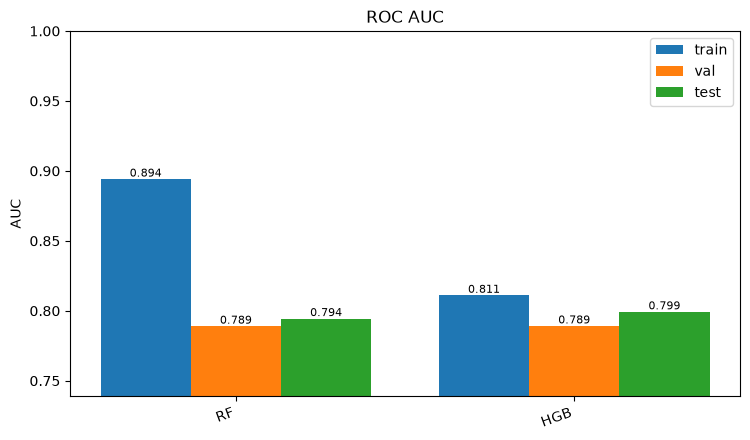

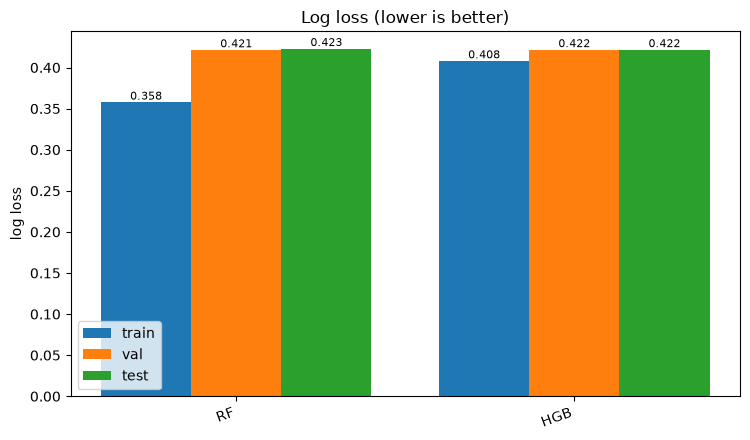

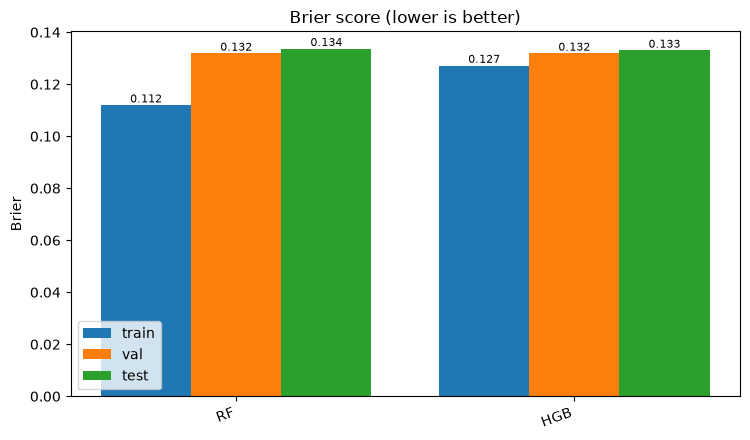

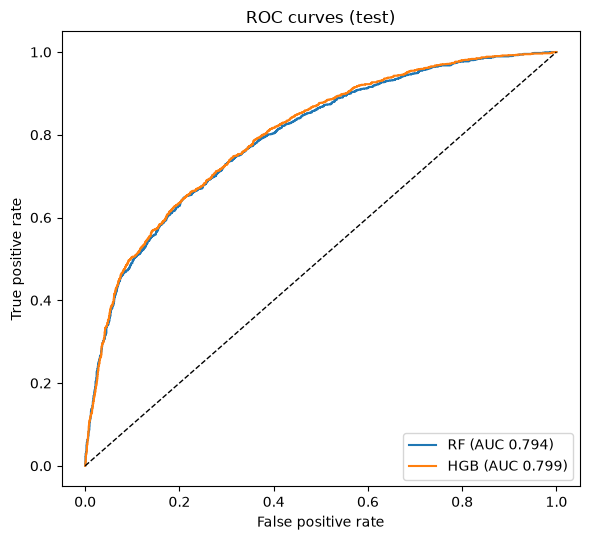

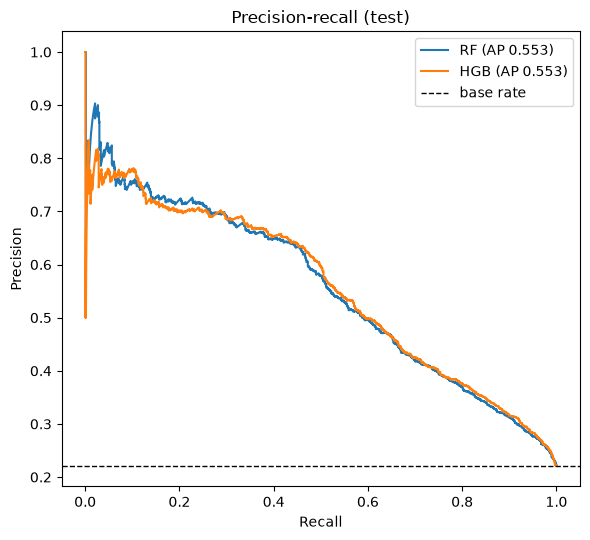

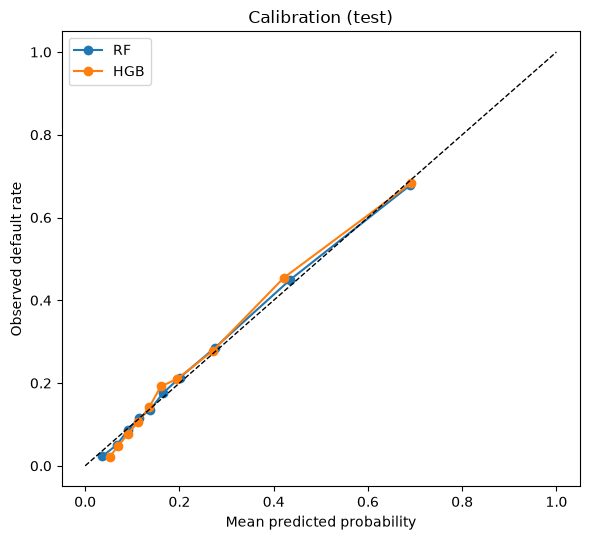

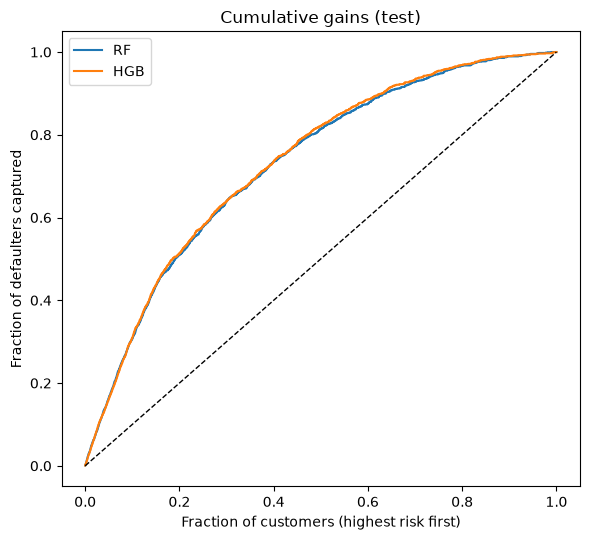

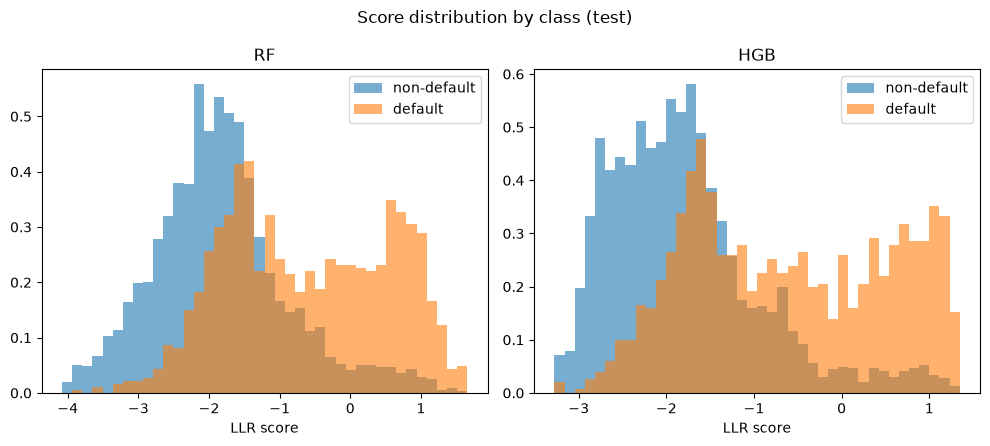

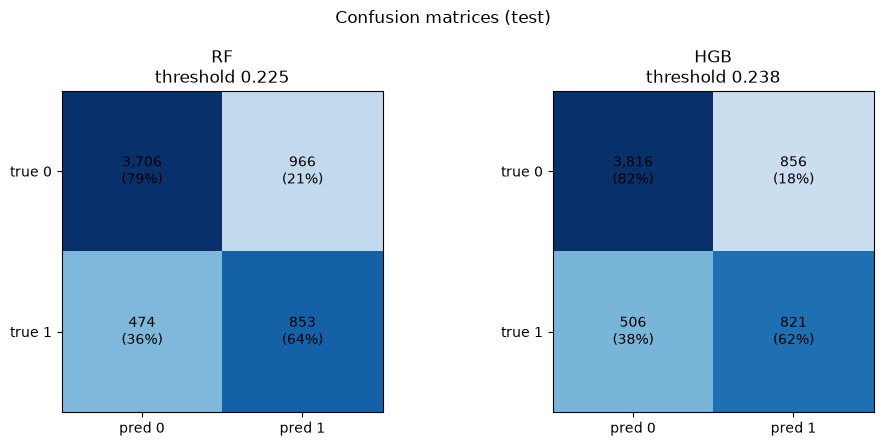

In [11]:
def as_result(model, eps=1e-6):
    out = {}
    for tag, X in [("tr", X_tr), ("va", X_va), ("te", X_te)]:
        p = model.predict_proba(X)[:, 1]
        out[f"p_{tag}"] = p
        pc = np.clip(p, eps, 1 - eps)
        out[f"sc_{tag}"] = np.log(pc / (1 - pc))   # log-odds, used by plot_score_distribution
    return out
results = {name: as_result(m) for name, m in models.items()}
auc_vals   = plot_auc(results)
ll_vals    = plot_logloss(results)
brier_vals = plot_brier(results)

plot_roc(results)
plot_pr(results)
plot_calibration(results)
plot_gains(results)
plot_score_distribution(results)
plot_confusion(results)          # threshold chosen on validation (Youden's J)

### Out of Bag AUC check

In [13]:
rf_oob = RandomForestClassifier(n_estimators=400, min_samples_leaf=20,
                                oob_score=True, n_jobs=-1, random_state=42)

rf_oob.fit(X_tr, y_tr)
oob_auc = roc_auc_score(y_tr, rf_oob.oob_decision_function_[:, 1])
print(f"Train AUC (in-bag) : {roc_auc_score(y_tr, rf_oob.predict_proba(X_tr)[:,1]):.3f}")
print(f"OOB AUC            : {oob_auc:.3f}")
print(f"Validation AUC     : {roc_auc_score(y_va, rf_oob.predict_proba(X_va)[:,1]):.3f}")

Train AUC (in-bag) : 0.894
OOB AUC            : 0.779
Validation AUC     : 0.789


### Validation Curve over min_samples_leaf

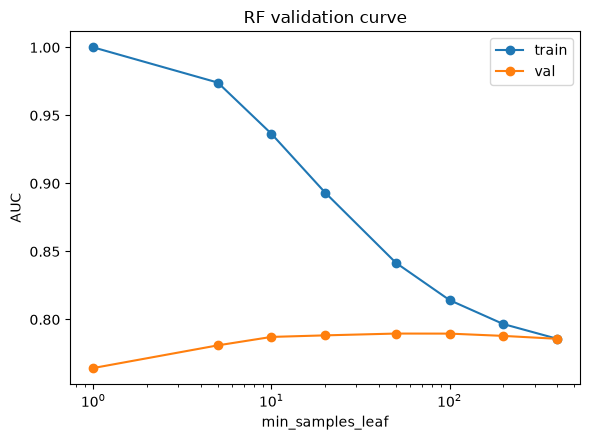

   min_samples_leaf   train     val
0                 1  1.0000  0.7643
1                 5  0.9741  0.7810
2                10  0.9365  0.7872
3                20  0.8933  0.7883
4                50  0.8416  0.7896
5               100  0.8142  0.7896
6               200  0.7967  0.7879
7               400  0.7859  0.7858


In [14]:
leaf_grid = [1, 5, 10, 20, 50, 100, 200, 400]
rows = []
for leaf in leaf_grid:
    m = RandomForestClassifier(n_estimators=200, min_samples_leaf=leaf,
                               n_jobs=-1, random_state=42).fit(X_tr, y_tr)
    rows.append({"min_samples_leaf": leaf,
                 "train": roc_auc_score(y_tr, m.predict_proba(X_tr)[:, 1]),
                 "val":   roc_auc_score(y_va, m.predict_proba(X_va)[:, 1])})
vc = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(6, 4.5))
ax.plot(vc.min_samples_leaf, vc.train, "o-", label="train")
ax.plot(vc.min_samples_leaf, vc.val, "o-", label="val")
ax.set_xscale("log"); ax.set_xlabel("min_samples_leaf"); ax.set_ylabel("AUC")
ax.set_title("RF validation curve"); ax.legend()
plt.tight_layout(); plt.show()
print(vc.round(4))

### Max-features sensitivity


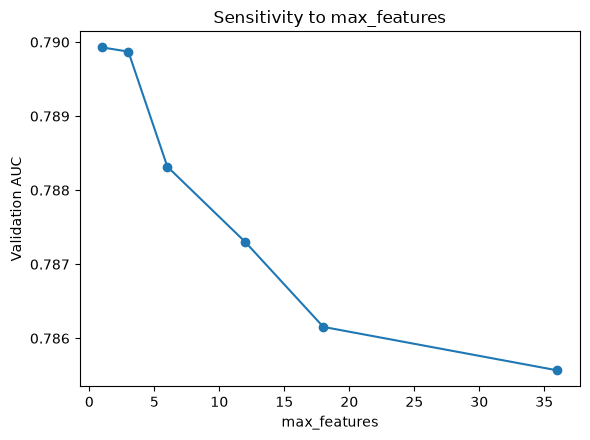

   max_features  val_auc
0             1   0.7899
1             3   0.7899
2             6   0.7883
3            12   0.7873
4            18   0.7862
5            36   0.7856


In [15]:
n_feat = X_tr.shape[1]
mf_grid = sorted({1, 3, int(np.sqrt(n_feat)), n_feat // 3, n_feat // 2, n_feat})
rows = []
for mf in mf_grid:
    m = RandomForestClassifier(n_estimators=200, min_samples_leaf=20,
                               max_features=mf, n_jobs=-1, random_state=42).fit(X_tr, y_tr)
    rows.append({"max_features": mf,
                 "val_auc": roc_auc_score(y_va, m.predict_proba(X_va)[:, 1])})
mf_df = pd.DataFrame(rows)
plt.figure(figsize=(6, 4.5)); plt.plot(mf_df.max_features, mf_df.val_auc, "o-")
plt.xlabel("max_features"); plt.ylabel("Validation AUC"); plt.title("Sensitivity to max_features")
plt.tight_layout(); plt.show()
print(mf_df.round(4))